<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta8g%C3%B6rev10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

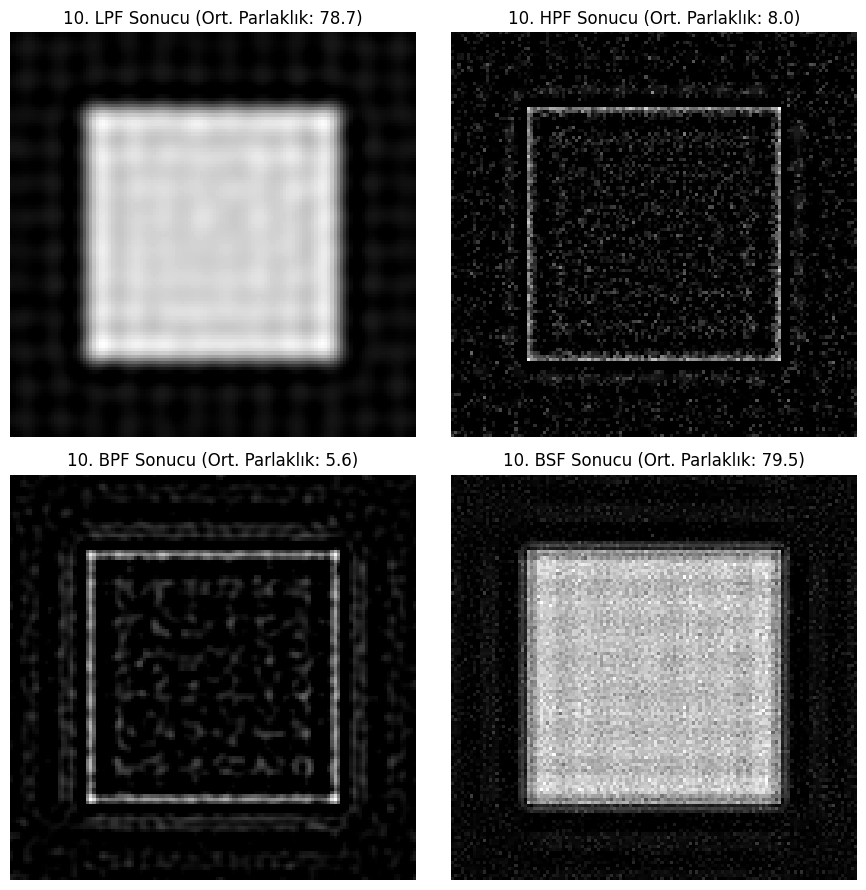

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def frekans_maske_uygula(goruntu, filtre_turu, d1=15.0, d2=40.0):
    M, N = goruntu.shape
    merkez_y, merkez_x = M // 2, N // 2
    y, x = np.ogrid[:M, :N]
    mesafe = np.sqrt((y - merkez_y) ** 2 + (x - merkez_x) ** 2)

    if filtre_turu == "lpf":
        maske = (mesafe <= d1).astype(np.float64)
    elif filtre_turu == "hpf":
        maske = (mesafe > d1).astype(np.float64)
    elif filtre_turu == "bpf":
        maske = ((mesafe >= d1) & (mesafe <= d2)).astype(np.float64)
    elif filtre_turu == "bsf":
        maske = (~((mesafe >= d1) & (mesafe <= d2))).astype(np.float64)
    else:
        raise ValueError("filtre_turu 'lpf', 'hpf', 'bpf' veya 'bsf' olmalıdır.")

    F = np.fft.fftshift(np.fft.fft2(goruntu.astype(np.float64)))
    F_sonuc = F * maske
    geri = np.real(np.fft.ifft2(np.fft.ifftshift(F_sonuc)))
    return np.clip(geri, 0, 255).astype(np.uint8)


y_idx, x_idx = np.ogrid[:128, :128]
rng = np.random.default_rng(15)
temiz = np.zeros((128, 128), dtype=np.uint8)
temiz[24:104, 24:104] = 190
gurultulu = np.clip(temiz.astype(np.float64) + rng.normal(0, 20, size=temiz.shape), 0, 255).astype(np.uint8)

plt.figure(figsize=(9, 9))
turler = ["lpf", "hpf", "bpf", "bsf"]
for i, tur in enumerate(turler, start=1):
    cikti = frekans_maske_uygula(gurultulu, tur, d1=12.0, d2=32.0)
    plt.subplot(2, 2, i)
    plt.imshow(cikti, cmap="gray")
    plt.title(f"10. {tur.upper()} Sonucu (Ort. Parlaklık: {np.mean(cikti):.1f})")
    plt.axis("off")

plt.tight_layout()
plt.show()